#  Analysis of the HBB Gene and Sickle Cell Mutation

## Introduction

The human HBB gene provides the instructions for producing the beta-globin subunit of haemoglobin. Haemoglobin is the protein in red blood cells responsible for carrying oxygen throughout the body.

Changes in the HBB gene can affect the structure of beta-globin and lead to inherited blood disorders. One well-known example is sickle cell disease, which is associated with a change in the HBB gene that results in an altered haemoglobin protein.

This project focuses on the HBB variant c.20A>T, which changes the normal codon GAG to GTG. This results in the amino acid glutamic acid being replaced by valine in the beta-globin protein. The altered haemoglobin is known as haemoglobin S (HbS).This change causes haemoglobin S molecules to stick together under low-oxygen conditions, forming fibres that make red blood cells become sickle-shaped and less flexible.
I chose this variant to explore how a small change in a nucleotide sequence can affect the resulting protein and how this change is connected to a genetic disease.

The aim of this project is to analyse the HBB reference sequence, identify its coding region, translate it into a protein, and simulate the sickle-cell-associated mutation to compare the normal and altered protein sequences.

In [ ]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 34.2 MB/s  0:00:00


In [ ]:
from Bio import Entrez, SeqIO
from Bio.SeqUtils import gc_fraction

In [ ]:
handle = Entrez.efetch(
    db="nuccore",
    id="NM_000518.5",
    rettype="gb",
    retmode="text"
)

hbb_record = SeqIO.read(handle, "genbank")
handle.close()

In [ ]:
print("Accession:", hbb_record.id)
print("Description:", hbb_record.description)
print("Sequence length:", len(hbb_record.seq), "nucleotides")

Accession: NM_000518.5
Description: Homo sapiens hemoglobin subunit beta (HBB), mRNA
Sequence length: 628 nucleotides


In [ ]:
print(hbb_record.seq)

ACATTTGCTTCTGACACAACTGTGTTCACTAGCAACCTCAAACAGACACCATGGTGCATCTGACTCCTGAGGAGAAGTCTGCCGTTACTGCCCTGTGGGGCAAGGTGAACGTGGATGAAGTTGGTGGTGAGGCCCTGGGCAGGCTGCTGGTGGTCTACCCTTGGACCCAGAGGTTCTTTGAGTCCTTTGGGGATCTGTCCACTCCTGATGCTGTTATGGGCAACCCTAAGGTGAAGGCTCATGGCAAGAAAGTGCTCGGTGCCTTTAGTGATGGCCTGGCTCACCTGGACAACCTCAAGGGCACCTTTGCCACACTGAGTGAGCTGCACTGTGACAAGCTGCACGTGGATCCTGAGAACTTCAGGCTCCTGGGCAACGTGCTGGTCTGTGTGCTGGCCCATCACTTTGGCAAAGAATTCACCCCACCAGTGCAGGCTGCCTATCAGAAAGTGGTGGCTGGTGTGGCTAATGCCCTGGCCCACAAGTATCACTAAGCTCGCTTTCTTGCTGTCCAATTTCTATTAAAGGTTCCTTTGTTCCCTAAGTCCAACTACTAAACTGGGGGATATTATGAAGGGCCTTGAGCATCTGGATTCTGCCTAATAAAAAACATTTATTTTCATTGCAA


In [ ]:
sequence = str(hbb_record.seq)

a_count = sequence.count("A")
t_count = sequence.count("T")
g_count = sequence.count("G")
c_count = sequence.count("C")

print("Adenine (A):", a_count)
print("Thymine (T):", t_count)
print("Guanine (G):", g_count)
print("Cytosine (C):", c_count)

Adenine (A): 139
Thymine (T): 167
Guanine (G): 165
Cytosine (C): 157


In [ ]:
gc_content = gc_fraction(hbb_record.seq) * 100

print("GC content:", round(gc_content, 2), "%")

GC content: 51.27 %


In [ ]:
valid_bases = set("ATGC")
sequence_bases = set(sequence)

unexpected_bases = sequence_bases - valid_bases

print("Unexpected characters:", unexpected_bases)

Unexpected characters: set()


In [ ]:
for feature in hbb_record.features:
    print(feature.type, feature.location)

source [0:628](+)
gene [0:628](+)
exon [0:142](+)
misc_feature [29:32](+)
CDS [50:494](+)
misc_feature [53:56](+)
misc_feature [53:56](+)
misc_feature [71:77](+)
misc_feature [74:77](+)
misc_feature [77:80](+)
misc_feature [86:89](+)
misc_feature [101:104](+)
misc_feature [125:131](+)
misc_feature [137:143](+)
mat_peptide [146:176](+)
mat_peptide [146:167](+)
misc_feature [155:161](+)
misc_feature [161:167](+)
misc_feature [182:185](+)
misc_feature [185:191](+)
misc_feature [200:203](+)
misc_feature [206:212](+)
misc_feature [218:224](+)
misc_feature [227:230](+)
misc_feature [227:230](+)
misc_feature [248:251](+)
misc_feature [263:269](+)
misc_feature [272:278](+)
misc_feature [296:299](+)
misc_feature [296:299](+)
misc_feature [302:308](+)
misc_feature [311:314](+)
misc_feature [326:332](+)
misc_feature [335:338](+)
misc_feature [362:368](+)
misc_feature [380:386](+)
misc_feature [407:413](+)
misc_feature [410:413](+)
misc_feature [416:422](+)
misc_feature [434:440](+)
misc_feature [

In [ ]:
cds_sequence = None

for feature in hbb_record.features:
    if feature.type == "CDS":
        cds_sequence = feature.extract(hbb_record.seq)
        break

print("CDS sequence:", cds_sequence)
print("CDS length:", len(cds_sequence), "nucleotides")

CDS sequence: ATGGTGCATCTGACTCCTGAGGAGAAGTCTGCCGTTACTGCCCTGTGGGGCAAGGTGAACGTGGATGAAGTTGGTGGTGAGGCCCTGGGCAGGCTGCTGGTGGTCTACCCTTGGACCCAGAGGTTCTTTGAGTCCTTTGGGGATCTGTCCACTCCTGATGCTGTTATGGGCAACCCTAAGGTGAAGGCTCATGGCAAGAAAGTGCTCGGTGCCTTTAGTGATGGCCTGGCTCACCTGGACAACCTCAAGGGCACCTTTGCCACACTGAGTGAGCTGCACTGTGACAAGCTGCACGTGGATCCTGAGAACTTCAGGCTCCTGGGCAACGTGCTGGTCTGTGTGCTGGCCCATCACTTTGGCAAAGAATTCACCCCACCAGTGCAGGCTGCCTATCAGAAAGTGGTGGCTGGTGTGGCTAATGCCCTGGCCCACAAGTATCACTAA
CDS length: 444 nucleotides


In [ ]:
print("CDS length:", len(cds_sequence))
print("First 30 nucleotides:", cds_sequence[:30])
print("Last 30 nucleotides:", cds_sequence[-30:])

CDS length: 444
First 30 nucleotides: ATGGTGCATCTGACTCCTGAGGAGAAGTCT
Last 30 nucleotides: GCTAATGCCCTGGCCCACAAGTATCACTAA


In [ ]:
print("Start codon:", cds_sequence[:3])
print("Stop codon:", cds_sequence[-3:])

Start codon: ATG
Stop codon: TAA


In [ ]:
normal_protein = cds_sequence.translate()

print("Normal HBB protein:")
print(normal_protein)
print("Protein sequence length:", len(normal_protein))

Normal HBB protein:
MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH*
Protein sequence length: 148


In [ ]:
normal_protein_clean = normal_protein.rstrip("*")

print("Protein length:", len(normal_protein_clean))
print("Protein sequence:", normal_protein_clean)

Protein length: 147
Protein sequence: MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH


In [ ]:
handle = Entrez.efetch(
    db="protein",
    id="NP_000509.1",
    rettype="fasta",
    retmode="text"
)

reference_protein_record = SeqIO.read(handle, "fasta")
handle.close()

reference_protein = str(reference_protein_record.seq)

print("Reference protein accession:", reference_protein_record.id)
print("Reference protein length:", len(reference_protein))

Reference protein accession: NP_000509.1
Reference protein length: 147


In [ ]:
if normal_protein_clean == reference_protein:
    print("The protein sequences are identical.")
else:
    print("The protein sequences are different.")

The protein sequences are identical.


## I introduced the c.20A>T substitution into the coding sequence. This changed the codon from GAG to GTG and replaced glutamic acid with valine at amino-acid position 7 (p.Glu7Val). The normal and altered protein sequences differed at one position, with 146 out of 147 amino-acid positions remaining identical.

In [ ]:
target_codon = cds_sequence[18:21]

print("Target codon:", target_codon)
print("CDS nucleotide positions: 19–21")

Target codon: GAG
CDS nucleotide positions: 19–21


In [ ]:
print("First nucleotide:", cds_sequence[18])
print("Second nucleotide:", cds_sequence[19])
print("Third nucleotide:", cds_sequence[20])

First nucleotide: G
Second nucleotide: A
Third nucleotide: G


In [ ]:
mutation_position = 20
mutation_index = mutation_position - 1

assert cds_sequence[mutation_index] == "A"

mutated_cds = (
    cds_sequence[:mutation_index]
    + "T"
    + cds_sequence[mutation_index + 1:]
)

print("Mutation position in CDS:", mutation_position)
print("Original nucleotide:", cds_sequence[mutation_index])
print("Mutated nucleotide:", mutated_cds[mutation_index])
print("Original codon:", cds_sequence[18:21])
print("Mutated codon:", mutated_cds[18:21])

Mutation position in CDS: 20
Original nucleotide: A
Mutated nucleotide: T
Original codon: GAG
Mutated codon: GTG


In [ ]:
print("Original CDS length:", len(cds_sequence))
print("Mutated CDS length:", len(mutated_cds))

print("Original nucleotide:", cds_sequence[19])
print("Mutated nucleotide:", mutated_cds[19])

print("Sequences have the same length:",
      len(cds_sequence) == len(mutated_cds))

Original CDS length: 444
Mutated CDS length: 444
Original nucleotide: A
Mutated nucleotide: T
Sequences have the same length: True


In [ ]:
mutated_protein = mutated_cds.translate()

print("Mutated HBB protein:")
print(mutated_protein)

print("Protein sequence length:", len(mutated_protein))

Mutated HBB protein:
MVHLTPVEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH*
Protein sequence length: 148


In [ ]:
mutated_protein_clean = mutated_protein.rstrip("*")

print("Mutated protein length:", len(mutated_protein_clean))
print("Mutated protein sequence:", mutated_protein_clean)

Mutated protein length: 147
Mutated protein sequence: MVHLTPVEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH


In [ ]:
print("Normal and mutated proteins are identical:",
      normal_protein_clean == mutated_protein_clean)

Normal and mutated proteins are identical: False


In [ ]:
for i in range(len(normal_protein_clean)):
    if normal_protein_clean[i] != mutated_protein_clean[i]:
        print("Position:", i + 1)
        print("Normal amino acid:", normal_protein_clean[i])
        print("Mutated amino acid:", mutated_protein_clean[i])

Position: 7
Normal amino acid: E
Mutated amino acid: V


In [ ]:
identical_positions = 0

for i in range(len(normal_protein_clean)):
    if normal_protein_clean[i] == mutated_protein_clean[i]:
        identical_positions += 1

total_positions = len(normal_protein_clean)

identity_percentage = (identical_positions / total_positions) * 100

print("Identical positions:", identical_positions)
print("Total positions:", total_positions)
print("Sequence identity:", round(identity_percentage, 2), "%")

Identical positions: 146
Total positions: 147
Sequence identity: 99.32 %


In [ ]:
print("HBB SEQUENCE ANALYSIS AND VARIANT RESULTS")
print("-----------------------------------------")

print("\nReference sequence")
print("Gene: HBB")
print("mRNA accession:", hbb_record.id)
print("mRNA length:", len(hbb_record.seq), "nucleotides")

print("\nCoding sequence")
print("CDS length:", len(cds_sequence), "nucleotides")
print("Start codon:", cds_sequence[:3])
print("Stop codon:", cds_sequence[-3:])

print("\nReference protein")
print("Protein accession:", reference_protein_record.id)
print("Protein length:", len(reference_protein), "amino acids")
print("Matches NCBI reference:",
      normal_protein_clean == reference_protein)

print("\nVariant investigated")
print("Gene: HBB")
print("Variant: NM_000518.5:c.20A>T")
print("Mutation position in CDS:", mutation_position)

print("\nSequence change")
print("Original nucleotide:", cds_sequence[mutation_index])
print("Altered nucleotide:", mutated_cds[mutation_index])
print("Original codon:", cds_sequence[18:21])
print("Altered codon:", mutated_cds[18:21])

print("\nProtein change")
print("Normal amino acid:", normal_protein_clean[6])
print("Altered amino acid:", mutated_protein_clean[6])
print("Protein notation: p.Glu7Val (E7V)")
print("Mature beta-globin notation: E6V")

print("\nProtein comparison")
print("Identical positions:", identical_positions)
print("Total positions:", total_positions)
print("Sequence identity:", round(identity_percentage, 2), "%")

HBB SEQUENCE ANALYSIS AND VARIANT RESULTS
-----------------------------------------

Reference sequence
Gene: HBB
mRNA accession: NM_000518.5
mRNA length: 628 nucleotides

Coding sequence
CDS length: 444 nucleotides
Start codon: ATG
Stop codon: TAA

Reference protein
Protein accession: NP_000509.1
Protein length: 147 amino acids
Matches NCBI reference: True

Variant investigated
Gene: HBB
Variant: NM_000518.5:c.20A>T
Mutation position in CDS: 20

Sequence change
Original nucleotide: A
Altered nucleotide: T
Original codon: GAG
Altered codon: GTG

Protein change
Normal amino acid: E
Altered amino acid: V
Protein notation: p.Glu7Val (E7V)
Mature beta-globin notation: E6V

Protein comparison
Identical positions: 146
Total positions: 147
Sequence identity: 99.32 %


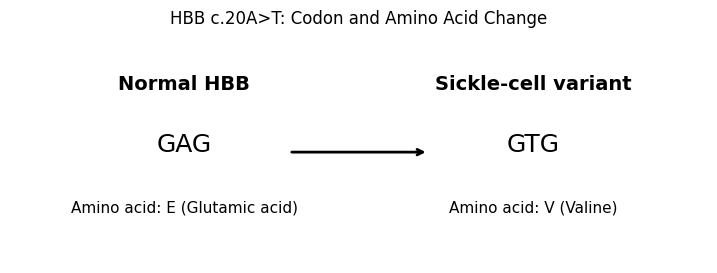

In [52]:
import matplotlib.pyplot as plt

normal_codon = cds_sequence[18:21]
mutated_codon = mutated_cds[18:21]

normal_amino_acid = normal_protein_clean[6]
mutated_amino_acid = mutated_protein_clean[6]

fig, ax = plt.subplots(figsize=(9, 3))
ax.axis("off")

ax.text(0.25, 0.75, "Normal HBB", ha="center", fontsize=14, weight="bold")
ax.text(0.25, 0.48, normal_codon, ha="center", fontsize=18)
ax.text(0.25, 0.22, f"Amino acid: {normal_amino_acid} (Glutamic acid)",
        ha="center", fontsize=11)

ax.text(0.75, 0.75, "Sickle-cell variant", ha="center",
        fontsize=14, weight="bold")
ax.text(0.75, 0.48, mutated_codon, ha="center", fontsize=18)
ax.text(0.75, 0.22, f"Amino acid: {mutated_amino_acid} (Valine)",
        ha="center", fontsize=11)

ax.annotate("", xy=(0.60, 0.48), xytext=(0.40, 0.48),
            arrowprops=dict(arrowstyle="->", lw=2))

plt.title("HBB c.20A>T: Codon and Amino Acid Change")
plt.show()

### ClinVar Evidence

I retrieved the HBB variant record from ClinVar using its Variation ID (15333).

ClinVar identifies the variant as NM_000518.5:c.20A>T, which produces the protein change p.Glu7Val. The record classifies this variant as pathogenic, with criteria provided by multiple submitters and no conflicting classifications.

|  |  |
|---|---|
| Gene | HBB |
| Variant | c.20A>T |
| Normal codon | GAG |
| Mutated codon | GTG |
| Amino acid change | Glutamic acid → Valine |
| Protein change | p.Glu7Val |
| ClinVar accession | VCV000015333 |
| Clinical significance | Pathogenic |

In [ ]:
from Bio import Entrez

handle = Entrez.efetch(
    db="clinvar",
    id="15333",
    rettype="vcv",
    retmode="xml",
    is_variationid="true"
)

clinvar_xml = handle.read()
handle.close()

import xml.etree.ElementTree as ET
root = ET.fromstring(clinvar_xml)

variation = root.find(".//VariationArchive")
print("ClinVar record retrieved successfully.")

ClinVar record retrieved successfully.


In [ ]:
classified_record = variation.find("ClassifiedRecord")
classifications = classified_record.find("Classifications")

print("CLINVAR EVIDENCE")
print("----------------")
print("Variation ID:", variation.get("VariationID"))
print("ClinVar accession:", variation.get("Accession"))

for element in variation.iter():
    if element.tag.split("}")[-1] == "Name" and element.text:
        if "NM_000518.5" in element.text:
            print("Variant:", element.text.strip())
            break

review_status = None
clinical_significance = None

for element in classifications.iter():
    tag = element.tag.split("}")[-1]

    if tag == "ReviewStatus" and review_status is None:
        review_status = element.text.strip()

    elif tag == "Description" and element.text:
        if element.text.strip() == "Pathogenic":
            clinical_significance = "Pathogenic"

print("Clinical significance:", clinical_significance)
print("Review status:", review_status)

CLINVAR EVIDENCE
----------------
Variation ID: 15333
ClinVar accession: VCV000015333
Variant: NM_000518.5(HBB):c.20A>T (p.Glu7Val)
Clinical significance: Pathogenic
Review status: criteria provided, multiple submitters, no conflicts


### Why Does This Mutation Cause Sickle Cell Disease?

The mutation replaces glutamic acid, which is negatively charged and hydrophilic (mixes well with water), with valine, which is hydrophobic (does not mix well with water). This changes a small but important part of the beta-globin protein.

When oxygen levels are low, haemoglobin S (HbS) molecules can stick together and form long fibres. This process is called polymerisation. These fibres can deform red blood cells into a sickle shape, making them less flexible.

The abnormal cells can break down more easily than normal red blood cells, which can cause anaemia. They may also block small blood vessels, reducing blood flow and causing painful episodes and, in some cases, damage to organs.

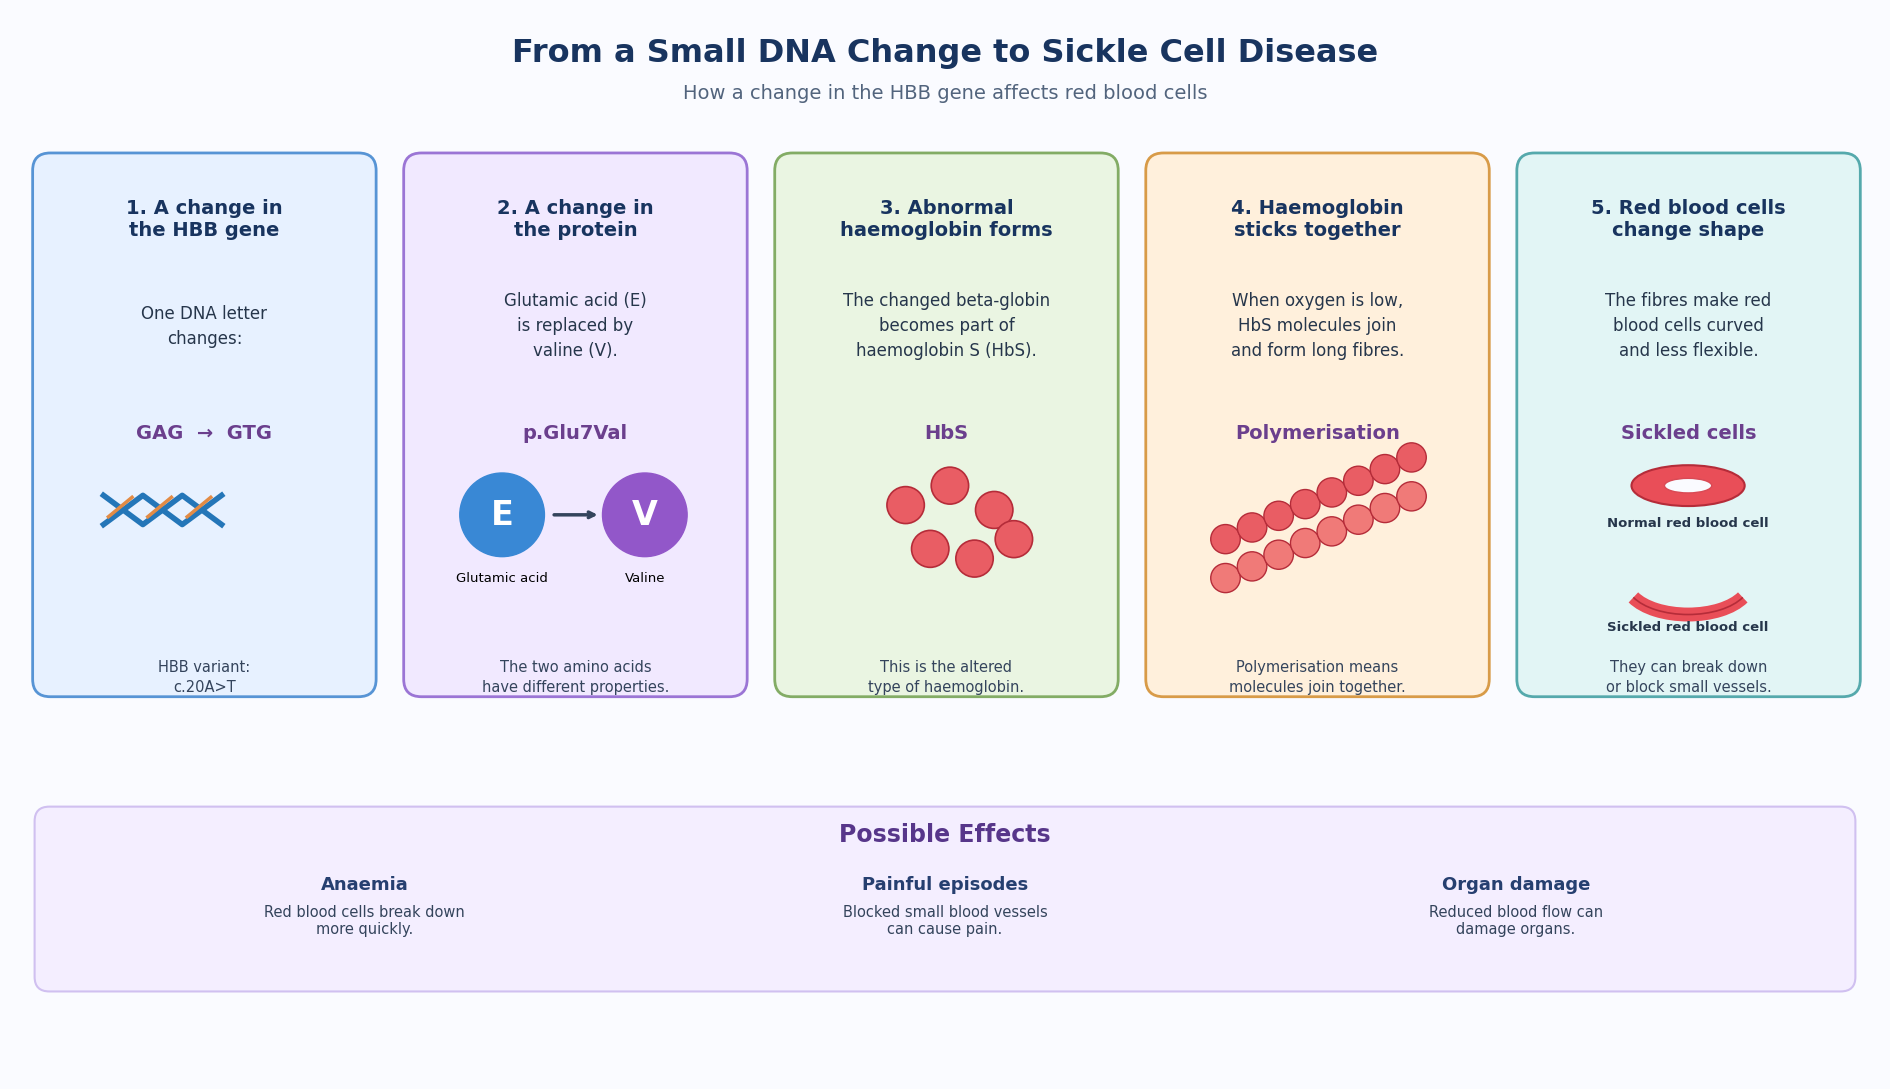

Diagram saved as HBB_Sickle_Cell_Diagram.png


In [63]:
import matplotlib.pyplot as plt
from matplotlib.patches import (
    FancyBboxPatch, FancyArrowPatch, Circle, Ellipse, Arc
)

fig, ax = plt.subplots(figsize=(19, 11))
fig.patch.set_facecolor("#FAFBFF")
ax.set_facecolor("#FAFBFF")

ax.set_xlim(0, 19)
ax.set_ylim(0, 11)
ax.axis("off")

ax.text(
    9.5, 10.55,
    "From a Small DNA Change to Sickle Cell Disease",
    ha="center", va="center",
    fontsize=23, fontweight="bold", color="#18345F"
)
ax.text(
    9.5, 10.08,
    "How a change in the HBB gene affects red blood cells",
    ha="center", fontsize=14, color="#52647D"
)

stages = [
    {
        "x": 0.35, "color": "#E7F1FF", "edge": "#5794D5",
        "title": "1. A change in\nthe HBB gene",
        "body": "One DNA letter\nchanges:",
        "detail": "GAG  →  GTG",
        "bottom": "HBB variant:\nc.20A>T"
    },
    {
        "x": 4.12, "color": "#F1E9FF", "edge": "#9B75D5",
        "title": "2. A change in\nthe protein",
        "body": "Glutamic acid (E)\nis replaced by\nvaline (V).",
        "detail": "p.Glu7Val",
        "bottom": "The two amino acids\nhave different properties."
    },
    {
        "x": 7.89, "color": "#EAF5E2", "edge": "#83AC65",
        "title": "3. Abnormal\nhaemoglobin forms",
        "body": "The changed beta-globin\nbecomes part of\nhaemoglobin S (HbS).",
        "detail": "HbS",
        "bottom": "This is the altered\ntype of haemoglobin."
    },
    {
        "x": 11.66, "color": "#FFF0DC", "edge": "#D89B48",
        "title": "4. Haemoglobin\nsticks together",
        "body": "When oxygen is low,\nHbS molecules join\nand form long fibres.",
        "detail": "Polymerisation",
        "bottom": "Polymerisation means\nmolecules join together."
    },
    {
        "x": 15.43, "color": "#E2F5F5", "edge": "#55A9AC",
        "title": "5. Red blood cells\nchange shape",
        "body": "The fibres make red\nblood cells curved\nand less flexible.",
        "detail": "Sickled cells",
        "bottom": "They can break down\nor block small vessels."
    }
]

panel_y = 4.05
panel_w = 3.25
panel_h = 5.35

for s in stages:
    panel = FancyBboxPatch(
        (s["x"], panel_y), panel_w, panel_h,
        boxstyle="round,pad=0.12,rounding_size=0.18",
        facecolor=s["color"], edgecolor=s["edge"],
        linewidth=2
    )
    ax.add_patch(panel)

    ax.text(
        s["x"] + panel_w/2, 8.85, s["title"],
        ha="center", va="center",
        fontsize=14, fontweight="bold", color="#18345F"
    )

    ax.text(
        s["x"] + panel_w/2, 7.75, s["body"],
        ha="center", va="center",
        fontsize=12, color="#26364B", linespacing=1.5
    )

    ax.text(
        s["x"] + panel_w/2, 6.65, s["detail"],
        ha="center", va="center",
        fontsize=14, fontweight="bold", color="#6B3F8D"
    )


    ax.text(
        s["x"] + panel_w/2, 4.32, s["bottom"],
        ha="center", va="top",
        fontsize=10.5, color="#34445C", linespacing=1.4
    )

ax.plot([0.95, 1.35, 1.75, 2.15], [6.0, 5.7, 6.0, 5.7],
        color="#2476B8", linewidth=4)
ax.plot([0.95, 1.35, 1.75, 2.15], [5.7, 6.0, 5.7, 6.0],
        color="#2476B8", linewidth=4)

for x, y in [(1.12, 5.88), (1.52, 5.88), (1.92, 5.88)]:
    ax.plot([x-0.12, x+0.12], [y-0.10, y+0.10],
            color="#E28B45", linewidth=2.5)

for x, color, letter in [
    (5.0, "#3988D5", "E"),
    (6.45, "#9257C9", "V")
]:
    ax.add_patch(Circle((x, 5.8), 0.43, color=color))
    ax.text(x, 5.8, letter, ha="center", va="center",
            color="white", fontsize=24, fontweight="bold")

ax.annotate(
    "", xy=(6.0, 5.8), xytext=(5.5, 5.8),
    arrowprops=dict(arrowstyle="->", lw=2.5, color="#34445C")
)
ax.text(5.0, 5.12, "Glutamic acid", ha="center", fontsize=9.5)
ax.text(6.45, 5.12, "Valine", ha="center", fontsize=9.5)

for x, y in [
    (9.1, 5.9), (9.55, 6.1), (10.0, 5.85),
    (9.35, 5.45), (9.8, 5.35), (10.2, 5.55)
]:
    ax.add_patch(Circle((x, y), 0.19,
                        facecolor="#E95D64", edgecolor="#B52C39",
                        linewidth=1.2))

for i in range(8):
    x = 12.35 + i * 0.27
    y = 5.55 + i * 0.12
    ax.add_patch(Circle((x, y), 0.15,
                        facecolor="#E95D64", edgecolor="#B52C39",
                        linewidth=1))

for i in range(8):
    x = 12.35 + i * 0.27
    y = 5.15 + i * 0.12
    ax.add_patch(Circle((x, y), 0.15,
                        facecolor="#F07A78", edgecolor="#B52C39",
                        linewidth=1))


ax.add_patch(Ellipse(
    (17.05, 6.10), 1.15, 0.42,
    facecolor="#E94E58",
    edgecolor="#B52C39",
    linewidth=1.5
))

ax.add_patch(Ellipse(
    (17.05, 6.10), 0.48, 0.15,
    facecolor="#FAFBFF",
    edgecolor="#D94A55",
    linewidth=1
))


ax.text(
    17.05, 5.72,
    "Normal red blood cell",
    ha="center", va="center",
    fontsize=9.5, color="#26364B", fontweight="bold"
)


ax.add_patch(Arc(
    (17.05, 5.10), 1.25, 0.65,
    theta1=195, theta2=345,
    linewidth=10, color="#E94E58"
))

ax.add_patch(Arc(
    (17.05, 5.10), 1.25, 0.65,
    theta1=195, theta2=345,
    linewidth=1.2, color="#B52C39"
))

ax.text(
    17.05, 4.65,
    "Sickled red blood cell",
    ha="center", va="center",
    fontsize=9.5, color="#26364B", fontweight="bold"
)


effects_box = FancyBboxPatch(
    (0.35, 1.0), 18.3, 1.7,
    boxstyle="round,pad=0.1,rounding_size=0.15",
    facecolor="#F4EEFF", edgecolor="#D0C0F0",
    linewidth=1.5
)
ax.add_patch(effects_box)

ax.text(
    9.5, 2.45, "Possible Effects",
    ha="center", fontsize=17, fontweight="bold",
    color="#57368A"
)

effects = [
    (3.6, "Anaemia", "Red blood cells break down\nmore quickly."),
    (9.5, "Painful episodes", "Blocked small blood vessels\ncan cause pain."),
    (15.3, "Organ damage", "Reduced blood flow can\ndamage organs.")
]

for x, heading, explanation in effects:
    ax.text(x, 1.95, heading, ha="center",
            fontsize=13, fontweight="bold", color="#263F70")
    ax.text(x, 1.50, explanation, ha="center",
            fontsize=10.5, color="#34445C")

ax.text(
    9.5, 0.55,
    "",
    ha="center", va="center", fontsize=10,
    color="#34445C", wrap=True
)

plt.tight_layout()

plt.savefig(
    "HBB_Sickle_Cell_Diagram.png",
    dpi=300, bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Diagram saved as HBB_Sickle_Cell_Diagram.png")

## Conclusion

In this project, I analysed the human HBB reference sequence and identified its coding region. I translated the coding sequence into a protein and compared it with the reference beta-globin protein.

I then simulated the sickle-cell-associated c.20A>T mutation. The change converted the codon GAG to GTG, resulting in the amino acid substitution glutamic acid to valine (p.Glu7Val).

The ClinVar record also identifies this variant as pathogenic. This analysis helped me understand how a single nucleotide change can alter a protein and contribute to a genetic disease.

## References

1. National Center for Biotechnology Information (NCBI). *Homo sapiens hemoglobin subunit beta (HBB), mRNA*. RefSeq accession: NM_000518.5.  
   https://www.ncbi.nlm.nih.gov/nuccore/NM_000518.5

2. National Center for Biotechnology Information (NCBI). *ClinVar: HBB c.20A>T (p.Glu7Val)*. Variation ID: 15333.  
   https://www.ncbi.nlm.nih.gov/clinvar/variation/15333/

3. Bender, M. A., et al. *Sickle Cell Disease*. GeneReviews®, NCBI Bookshelf.  
   https://www.ncbi.nlm.nih.gov/books/NBK1377/